In [1]:
# ======================================================================
# 01 | Experiment Design and Business Objective
# ======================================================================

from pathlib import Path
import json, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit, ParameterSampler
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    confusion_matrix, brier_score_loss,
    precision_recall_curve, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.dummy import DummyClassifier
from xgboost import XGBClassifier

SEED = 42
rng = np.random.default_rng(SEED)

ROOT = Path.cwd()
if not (ROOT / "datasets").exists():
    ROOT = ROOT.parent

DATA = ROOT / "datasets/processed"
RAW = ROOT / "datasets/raw"
REPORTS = ROOT / "reports"
MODELS = ROOT / "models"

REPORTS.mkdir(exist_ok=True, parents=True)
MODELS.mkdir(exist_ok=True, parents=True)

sns.set_theme(style="whitegrid")

"""
BUSINESS QUESTION
At order approval, which delivered orders are at risk
of arriving after their estimated delivery date?

PRIMARY METRIC
Recall among the highest-risk 20% of orders.

SECONDARY METRICS
PR-AUC, ROC-AUC, Precision@20%, lift, calibration.

DESIGN LIMITATIONS
- Historical retrospective evaluation
- Delivered-order selection bias
- No causal inference
- No deployment claims
- Test period already inspected in earlier experiments:
  comparisons are retrospective, not fresh blind validation.
"""

ALERT_BUDGET = 0.20

print("RetailAI | Advanced Delivery Risk Evaluation")
print("Primary metric: Recall@20%")
print("Prediction stage: post approval")

RetailAI | Advanced Delivery Risk Evaluation
Primary metric: Recall@20%
Prediction stage: post approval


In [2]:
# ======================================================================
# 02 | Load Sources and Verify Contracts
# ======================================================================

def read_table(name):
    processed = DATA / f"{name}.parquet"
    if processed.exists():
        return pd.read_parquet(processed)

    raw_matches = list(RAW.glob(f"*{name}*.csv"))
    if raw_matches:
        return pd.read_csv(raw_matches[0])

    raise FileNotFoundError(f"Missing dataset: {name}")

orders = read_table("orders")
items = read_table("order_items")
customers = read_table("customers")
products = read_table("products")
sellers = read_table("sellers")

required = {
    "orders": (orders, [
        "order_id", "customer_id", "order_status",
        "order_purchase_timestamp", "order_approved_at",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]),
    "items": (items, [
        "order_id", "product_id", "seller_id",
        "price", "freight_value"
    ]),
    "customers": (customers, [
        "customer_id", "customer_state"
    ]),
    "products": (products, ["product_id"]),
    "sellers": (sellers, ["seller_id"])
}

for name, (frame, cols) in required.items():
    missing = set(cols) - set(frame.columns)
    assert not missing, f"{name}: missing {missing}"

for c in [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")

assert orders.order_id.is_unique
assert customers.customer_id.is_unique
assert products.product_id.is_unique
assert sellers.seller_id.is_unique

for c in ["price", "freight_value"]:
    items[c] = pd.to_numeric(items[c], errors="coerce")

display(pd.DataFrame([
    {"table": n, "rows": len(f), "columns": len(f.columns)}
    for n, f in [
        ("orders", orders), ("items", items),
        ("customers", customers),
        ("products", products), ("sellers", sellers)
    ]
]))

,table,rows,columns
0,orders,99441,8
1,items,112650,7
2,customers,99441,5
3,products,32951,9
4,sellers,3095,4


In [3]:
# ======================================================================
# 03 | Product and Geographic Feature Engineering
# ======================================================================

# All item-level features are aggregated to one row per order.

product_cols = [
    c for c in [
        "product_id", "product_weight_g",
        "product_length_cm", "product_height_cm",
        "product_width_cm", "product_category_name"
    ] if c in products.columns
]

product_info = products[product_cols].copy()

for c in [
    "product_weight_g", "product_length_cm",
    "product_height_cm", "product_width_cm"
]:
    if c not in product_info:
        product_info[c] = np.nan
    product_info[c] = pd.to_numeric(
        product_info[c], errors="coerce"
    )

product_info["product_volume_cm3"] = (
    product_info.product_length_cm
    * product_info.product_height_cm
    * product_info.product_width_cm
)

item_detail = items.merge(
    product_info,
    on="product_id",
    how="left",
    validate="many_to_one"
)

item_detail["total_item_value"] = (
    item_detail.price + item_detail.freight_value
)

item_features = item_detail.groupby("order_id").agg(
    item_count=("product_id", "size"),
    unique_products=("product_id", "nunique"),
    unique_sellers=("seller_id", "nunique"),
    total_item_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    mean_product_weight=("product_weight_g", "mean"),
    max_product_weight=("product_weight_g", "max"),
    total_product_volume=("product_volume_cm3", "sum"),
    mean_product_volume=("product_volume_cm3", "mean")
).reset_index()

# Geographic proxy: first seller location in each order.
# Multi-seller orders have an approximate origin only.

seller_geo_cols = [
    c for c in [
        "seller_id", "seller_zip_code_prefix",
        "seller_state"
    ] if c in sellers.columns
]

seller_info = sellers[seller_geo_cols].copy()

first_seller = (
    items.sort_values(["order_id", "order_item_id"])
    .drop_duplicates("order_id")
    [["order_id", "seller_id"]]
    .merge(seller_info, on="seller_id", how="left")
)

customer_cols = [
    c for c in [
        "customer_id", "customer_state",
        "customer_zip_code_prefix"
    ] if c in customers.columns
]

base = (
    orders
    .merge(
        customers[customer_cols],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        item_features,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        first_seller,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

base["same_seller_customer_state"] = (
    base.get("seller_state", pd.Series(index=base.index))
    == base.customer_state
).astype(float)

# Approximate distance using ZIP centroid coordinates if available.
geo_paths = [
    DATA / "geolocation.parquet",
    RAW / "olist_geolocation_dataset.csv",
    RAW / "geolocation.csv"
]

geo_path = next(
    (p for p in geo_paths if p.exists()),
    None
)

base["approx_distance_km"] = np.nan

if geo_path is not None:
    geo = (
        pd.read_parquet(geo_path)
        if geo_path.suffix == ".parquet"
        else pd.read_csv(geo_path)
    )

    required_geo = {
        "geolocation_zip_code_prefix",
        "geolocation_lat",
        "geolocation_lng"
    }

    if required_geo.issubset(geo.columns) and all(
        c in base.columns for c in [
            "customer_zip_code_prefix",
            "seller_zip_code_prefix"
        ]
    ):
        centroids = (
            geo.groupby("geolocation_zip_code_prefix")
            [["geolocation_lat", "geolocation_lng"]]
            .median()
            .reset_index()
        )

        customer_geo = centroids.rename(columns={
            "geolocation_zip_code_prefix": "customer_zip_code_prefix",
            "geolocation_lat": "customer_lat",
            "geolocation_lng": "customer_lng"
        })

        seller_geo = centroids.rename(columns={
            "geolocation_zip_code_prefix": "seller_zip_code_prefix",
            "geolocation_lat": "seller_lat",
            "geolocation_lng": "seller_lng"
        })

        base = base.merge(
            customer_geo,
            on="customer_zip_code_prefix",
            how="left",
            validate="many_to_one"
        ).merge(
            seller_geo,
            on="seller_zip_code_prefix",
            how="left",
            validate="many_to_one"
        )

        lat1 = np.radians(base.customer_lat)
        lat2 = np.radians(base.seller_lat)
        dlat = lat2 - lat1
        dlon = np.radians(
            base.seller_lng - base.customer_lng
        )

        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(lat1) * np.cos(lat2)
            * np.sin(dlon / 2) ** 2
        )

        base["approx_distance_km"] = (
            6371 * 2 * np.arcsin(
                np.sqrt(np.clip(a, 0, 1))
            )
        )

assert base.order_id.is_unique
assert len(base) == len(orders)

print("Order-grain rows:", len(base))
print("Distance coverage:",
      base.approx_distance_km.notna().mean())

Order-grain rows: 99441
Distance coverage: 0.9872688327752135


In [4]:
# ======================================================================
# 04 | Target, Prediction Time and Leakage Audit
# ======================================================================

df = base.loc[
    base.order_status.eq("delivered")
].copy()

df = df.dropna(subset=[
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
])

df["actual_days"] = (
    df.order_delivered_customer_date
    - df.order_purchase_timestamp
).dt.total_seconds() / 86400

df["promised_days"] = (
    df.order_estimated_delivery_date
    - df.order_purchase_timestamp
).dt.total_seconds() / 86400

df = df.loc[
    df.actual_days.ge(0)
    & df.promised_days.gt(0)
].copy()

df["late_delivery"] = (
    df.order_delivered_customer_date
    > df.order_estimated_delivery_date
).astype(int)

df["purchase_month"] = (
    df.order_purchase_timestamp.dt.month
)
df["purchase_weekday"] = (
    df.order_purchase_timestamp.dt.dayofweek
)
df["purchase_hour"] = (
    df.order_purchase_timestamp.dt.hour
)

df["approval_lag_hours"] = (
    df.order_approved_at
    - df.order_purchase_timestamp
).dt.total_seconds() / 3600

df.loc[
    df.approval_lag_hours.lt(0),
    "approval_lag_hours"
] = np.nan

# Do not include actual delivery, review, or carrier timestamps.
numeric_features = [
    "promised_days",
    "approval_lag_hours",
    "item_count",
    "unique_products",
    "unique_sellers",
    "total_item_price",
    "total_freight",
    "mean_product_weight",
    "max_product_weight",
    "total_product_volume",
    "mean_product_volume",
    "approx_distance_km",
    "same_seller_customer_state",
    "purchase_month",
    "purchase_weekday",
    "purchase_hour"
]

categorical_features = [
    c for c in [
        "customer_state", "seller_state"
    ] if c in df.columns
]

for c in numeric_features:
    if c not in df:
        df[c] = np.nan

for c in numeric_features:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    df[c] = df[c].replace([np.inf, -np.inf], np.nan)

for c in categorical_features:
    df[c] = df[c].fillna("UNKNOWN").astype(str)

forbidden = {
    "late_delivery",
    "actual_days",
    "order_delivered_customer_date",
    "order_delivered_carrier_date",
    "review_score",
    "order_status"
}

assert not forbidden.intersection(
    numeric_features + categorical_features
)

assert df.late_delivery.nunique() == 2

print("Delivered orders:", len(df))
print("Late rate:", round(df.late_delivery.mean(), 4))
print("Leakage blacklist passed.")

Delivered orders: 96456
Late rate: 0.0811
Leakage blacklist passed.


In [5]:
# ======================================================================
# 05 | Leakage-Safe Historical Seller Reliability
# ======================================================================

"""
Seller history must be known BEFORE the current order
is approved.

A historical order is eligible only when its delivery
was completed before the prediction timestamp.

This prevents using future delivery outcomes.
"""

seller_events = (
    df[[
        "seller_id",
        "order_id",
        "order_delivered_customer_date",
        "late_delivery"
    ]]
    .dropna(subset=[
        "seller_id",
        "order_delivered_customer_date"
    ])
    .sort_values([
        "order_delivered_customer_date", "order_id"
    ])
    .copy()
)

seller_events["history_count"] = (
    seller_events.groupby("seller_id").cumcount() + 1
)

seller_events["history_late_count"] = (
    seller_events.groupby("seller_id")[
        "late_delivery"
    ].cumsum()
)

# Same delivery timestamp may occur for multiple orders.
# Collapse to one final cumulative record per seller/timestamp.
seller_events = (
    seller_events.sort_values([
        "seller_id",
        "order_delivered_customer_date",
        "history_count"
    ])
    .drop_duplicates(
        ["seller_id", "order_delivered_customer_date"],
        keep="last"
    )
)

left = df[[
    "order_id", "seller_id", "order_approved_at"
]].copy()

left = left.rename(columns={
    "order_approved_at": "prediction_timestamp"
})

left = left.sort_values("prediction_timestamp")

right = seller_events[[
    "seller_id",
    "order_delivered_customer_date",
    "history_count",
    "history_late_count"
]].rename(columns={
    "order_delivered_customer_date": "history_timestamp"
})

right = right.sort_values("history_timestamp")

history = pd.merge_asof(
    left,
    right,
    left_on="prediction_timestamp",
    right_on="history_timestamp",
    by="seller_id",
    direction="backward",
    allow_exact_matches=False
)

assert (
    history.history_timestamp.dropna()
    < history.loc[
        history.history_timestamp.notna(),
        "prediction_timestamp"
    ]
).all()

history["seller_prior_orders"] = (
    history.history_count.fillna(0)
)

# Bayesian smoothing towards the training-period-independent
# neutral prior 0.10; a tunable modeling assumption.
PRIOR_RATE = 0.10
PRIOR_STRENGTH = 20

history["seller_prior_late_rate"] = (
    history.history_late_count.fillna(0)
    + PRIOR_RATE * PRIOR_STRENGTH
) / (
    history.history_count.fillna(0)
    + PRIOR_STRENGTH
)

df = df.merge(
    history[[
        "order_id",
        "seller_prior_orders",
        "seller_prior_late_rate"
    ]],
    on="order_id",
    how="left",
    validate="one_to_one"
)

numeric_features += [
    "seller_prior_orders",
    "seller_prior_late_rate"
]

assert df.order_id.is_unique

print("Historical seller features generated.")
display(
    df[[
        "seller_prior_orders",
        "seller_prior_late_rate"
    ]].describe()
)

Historical seller features generated.


,seller_prior_orders,seller_prior_late_rate
count,96456.000000,96456.000000
mean,169.536255,0.073754
std,283.406076,0.035886
min,0.000000,0.008811
25%,12.000000,0.047619
50%,51.000000,0.068966
75%,180.000000,0.095238
max,1788.000000,0.369231


In [6]:
# ======================================================================
# 06 | Chronological Splits and Distribution Shift
# ======================================================================

df = df.sort_values(
    ["order_purchase_timestamp", "order_id"]
).reset_index(drop=True)

n = len(df)
train_end = int(n * 0.70)
valid_end = int(n * 0.85)

train = df.iloc[:train_end].copy()
valid = df.iloc[train_end:valid_end].copy()
test = df.iloc[valid_end:].copy()

features = numeric_features + categorical_features

X_train = train[features]
X_valid = valid[features]
X_test = test[features]

y_train = train.late_delivery
y_valid = valid.late_delivery
y_test = test.late_delivery

assert (
    train.order_purchase_timestamp.max()
    <= valid.order_purchase_timestamp.min()
)
assert (
    valid.order_purchase_timestamp.max()
    <= test.order_purchase_timestamp.min()
)

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "late_rate": frame.late_delivery.mean(),
        "start": frame.order_purchase_timestamp.min(),
        "end": frame.order_purchase_timestamp.max()
    }
    for name, frame in [
        ("train", train),
        ("validation", valid),
        ("test", test)
    ]
])

display(summary)

print("Prevalence shift:")
print(
    "Train -> validation:",
    round(y_valid.mean() - y_train.mean(), 4)
)
print(
    "Validation -> test:",
    round(y_test.mean() - y_valid.mean(), 4)
)

,split,rows,late_rate,start,end
0,train,67519,0.090286,2016-09-15 12:16:38,2018-04-15 20:23:05
1,validation,14468,0.053428,2018-04-15 20:24:52,2018-06-21 08:45:30
2,test,14469,0.066141,2018-06-21 08:46:52,2018-08-29 15:00:37


Prevalence shift:
Train -> validation: -0.0369
Validation -> test: 0.0127


In [7]:
# ======================================================================
# 07 | Fold-Safe Preprocessing and Baselines
# ======================================================================

def build_preprocessor():
    return ColumnTransformer([
        (
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scale", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="UNKNOWN"
                    )
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    )
                )
            ]),
            categorical_features
        )
    ])

def recall_at_budget(y, scores, budget=0.20):
    y = np.asarray(y)
    scores = np.asarray(scores)
    k = max(1, int(np.ceil(len(y) * budget)))
    chosen = np.argsort(-scores, kind="stable")[:k]
    positives = y.sum()
    return (
        float(y[chosen].sum() / positives)
        if positives else np.nan
    )

def precision_at_budget(y, scores, budget=0.20):
    y = np.asarray(y)
    k = max(1, int(np.ceil(len(y) * budget)))
    chosen = np.argsort(
        -np.asarray(scores),
        kind="stable"
    )[:k]
    return float(y[chosen].mean())

def evaluate(y, scores):
    return {
        "pr_auc": average_precision_score(y, scores),
        "roc_auc": roc_auc_score(y, scores),
        "recall_at_20": recall_at_budget(y, scores),
        "precision_at_20": precision_at_budget(y, scores),
        "lift_at_20": (
            precision_at_budget(y, scores)
            / np.mean(y)
        ),
        "brier": brier_score_loss(y, scores)
    }

def pipeline_for(estimator):
    return Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", estimator)
    ])

baseline = pipeline_for(
    DummyClassifier(strategy="prior")
)
baseline.fit(X_train, y_train)

baseline_prob = baseline.predict_proba(X_valid)[:, 1]

print("Dummy baseline")
display(pd.DataFrame([evaluate(y_valid, baseline_prob)]))

Dummy baseline


,pr_auc,roc_auc,recall_at_20,precision_at_20,lift_at_20,brier
0,0.053428,0.5,0.164295,0.043884,0.821361,0.051932


In [8]:
# ======================================================================
# 08 | Candidate Models and Temporal Cross-Validation
# ======================================================================

"""
Preprocessing is fitted inside each CV fold.

Use a small time-aware parameter search to keep
runtime practical on a MacBook Air.
"""

candidates = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter=2500,
            class_weight="balanced",
            random_state=SEED
        ),
        {"model__C": [0.1, 1, 5]}
    ),
    "Random Forest": (
        RandomForestClassifier(
            n_estimators=250,
            n_jobs=-1,
            class_weight="balanced_subsample",
            random_state=SEED
        ),
        {
            "model__max_depth": [8, 14, None],
            "model__min_samples_leaf": [5, 15, 30]
        }
    ),
    "XGBoost": (
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            n_jobs=3,
            random_state=SEED
        ),
        {
            "model__n_estimators": [200, 350],
            "model__max_depth": [3, 5],
            "model__learning_rate": [0.03, 0.08],
            "model__min_child_weight": [3, 8]
        }
    ),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(
            random_state=SEED
        ),
        {
            "model__max_iter": [150, 250],
            "model__learning_rate": [0.04, 0.08],
            "model__max_leaf_nodes": [15, 31]
        }
    )
}

cv = TimeSeriesSplit(n_splits=3)
cv_rows = []
best_params = {}

for name, (estimator, space) in candidates.items():
    print("\nTuning:", name)

    configs = list(ParameterSampler(
        space,
        n_iter=min(4, np.prod([
            len(v) for v in space.values()
        ])),
        random_state=SEED
    ))

    for config in configs:
        fold_scores = []

        for train_idx, val_idx in cv.split(X_train):
            model = pipeline_for(
                estimator.__class__(**estimator.get_params())
            )
            model.set_params(**config)

            model.fit(
                X_train.iloc[train_idx],
                y_train.iloc[train_idx]
            )

            scores = model.predict_proba(
                X_train.iloc[val_idx]
            )[:, 1]

            fold_scores.append(
                recall_at_budget(
                    y_train.iloc[val_idx],
                    scores,
                    ALERT_BUDGET
                )
            )

        cv_rows.append({
            "model": name,
            "parameters": config,
            "cv_recall_at_20": np.nanmean(fold_scores),
            "cv_std": np.nanstd(fold_scores)
        })

cv_results = pd.DataFrame(cv_rows)

for name in candidates:
    subset = cv_results[
        cv_results.model.eq(name)
    ].sort_values("cv_recall_at_20", ascending=False)

    best_params[name] = subset.iloc[0]["parameters"]

display(
    cv_results.sort_values(
        "cv_recall_at_20",
        ascending=False
    ).head(12)
)


Tuning: Logistic Regression



Tuning: Random Forest



Tuning: XGBoost



Tuning: HistGradientBoosting


,model,parameters,cv_recall_at_20,cv_std
6,Random Forest,"{'model__min_samples_leaf': 5, 'model__max_dep...",0.393176,0.021985
4,Random Forest,"{'model__min_samples_leaf': 15, 'model__max_de...",0.389004,0.025872
3,Random Forest,"{'model__min_samples_leaf': 15, 'model__max_de...",0.382723,0.016953
5,Random Forest,"{'model__min_samples_leaf': 30, 'model__max_de...",0.382465,0.021685
0,Logistic Regression,{'model__C': 0.1},0.378197,0.041725
2,Logistic Regression,{'model__C': 5},0.376537,0.041420
1,Logistic Regression,{'model__C': 1},0.375739,0.041037
8,XGBoost,"{'model__n_estimators': 350, 'model__min_child...",0.360834,0.012196
7,XGBoost,"{'model__n_estimators': 200, 'model__min_child...",0.357883,0.005078
10,XGBoost,"{'model__n_estimators': 200, 'model__min_child...",0.354915,0.022044


In [9]:
# ======================================================================
# 09 | Fit Final Candidates and Compare Validation
# ======================================================================

fitted = {"Dummy Baseline": baseline}
valid_predictions = {
    "Dummy Baseline": baseline_prob
}

rows = [{
    "model": "Dummy Baseline",
    **evaluate(y_valid, baseline_prob)
}]

for name, (estimator, _) in candidates.items():
    model = pipeline_for(
        estimator.__class__(**estimator.get_params())
    )
    model.set_params(**best_params[name])
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_valid)[:, 1]

    fitted[name] = model
    valid_predictions[name] = probabilities

    rows.append({
        "model": name,
        **evaluate(y_valid, probabilities)
    })

comparison = pd.DataFrame(rows).sort_values(
    ["recall_at_20", "pr_auc"],
    ascending=[False, False]
)

display(comparison)

selected_name = comparison.iloc[0]["model"]
selected_model = fitted[selected_name]
selected_valid_prob = valid_predictions[selected_name]

print("Selected model:", selected_name)
print("Selection metric: Validation Recall@20%")

,model,pr_auc,roc_auc,recall_at_20,precision_at_20,lift_at_20,brier
1,Logistic Regression,0.150711,0.752599,0.508409,0.135798,2.541693,0.257388
3,XGBoost,0.158850,0.754720,0.507115,0.135453,2.535225,0.047975
4,HistGradientBoosting,0.152272,0.732152,0.490298,0.130961,2.451149,0.048223
2,Random Forest,0.124530,0.718726,0.460543,0.123013,2.302398,0.169330
0,Dummy Baseline,0.053428,0.500000,0.164295,0.043884,0.821361,0.051932


Selected model: Logistic Regression
Selection metric: Validation Recall@20%


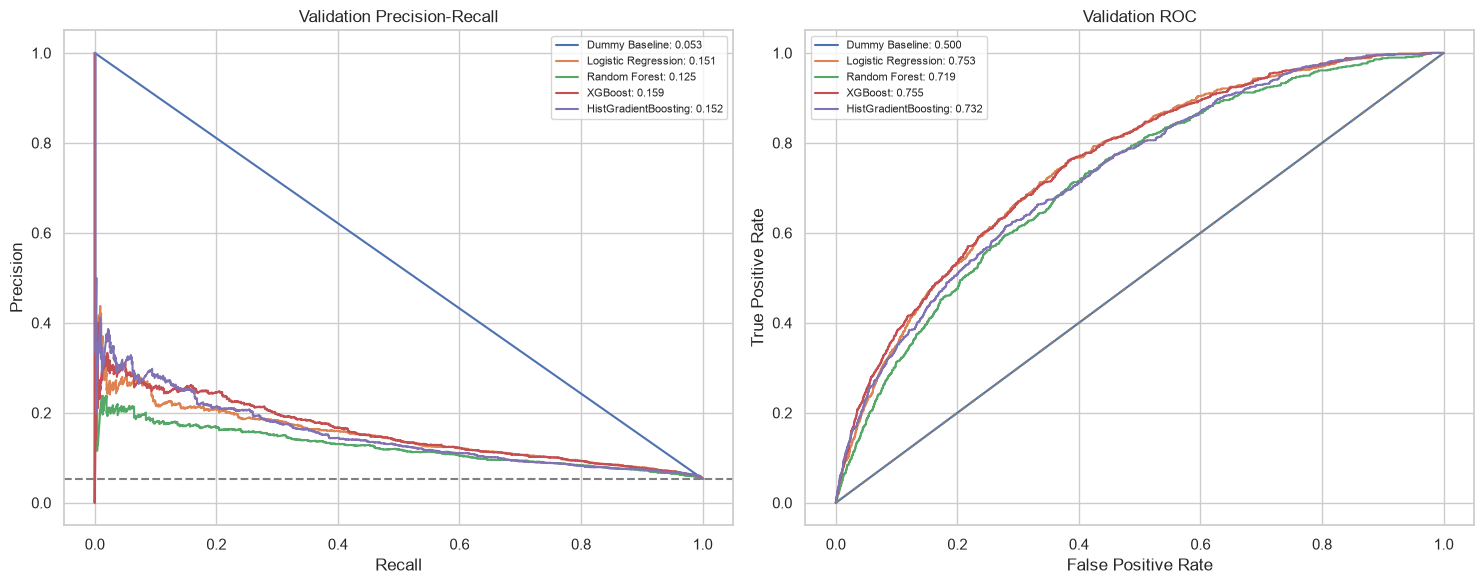

alert_budget,0.05,0.10,0.15,0.20,0.25
model,,,,,
Dummy Baseline,0.045278,0.085382,0.120310,0.164295,0.203105
HistGradientBoosting,0.200517,0.322122,0.402329,0.490298,0.549806
Logistic Regression,0.194049,0.324709,0.428202,0.508409,0.582147
Random Forest,0.160414,0.285899,0.379043,0.460543,0.529107
XGBoost,0.217335,0.346701,0.432083,0.507115,0.580854


In [10]:
# ======================================================================
# 10 | Precision-Recall, ROC and Alert Capacity
# ======================================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name, prob in valid_predictions.items():
    precision, recall, _ = precision_recall_curve(
        y_valid, prob
    )
    fpr, tpr, _ = roc_curve(y_valid, prob)

    axes[0].plot(
        recall, precision,
        label=f"{name}: {average_precision_score(y_valid, prob):.3f}"
    )
    axes[1].plot(
        fpr, tpr,
        label=f"{name}: {roc_auc_score(y_valid, prob):.3f}"
    )

axes[0].axhline(
    y_valid.mean(), linestyle="--", color="gray"
)
axes[0].set_title("Validation Precision-Recall")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")

axes[1].plot(
    [0, 1], [0, 1],
    linestyle="--", color="gray"
)
axes[1].set_title("Validation ROC")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")

for ax in axes:
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

capacity_rows = []

for name, prob in valid_predictions.items():
    for budget in [0.05, 0.10, 0.15, 0.20, 0.25]:
        capacity_rows.append({
            "model": name,
            "alert_budget": budget,
            "recall_at_k": recall_at_budget(
                y_valid, prob, budget
            ),
            "precision_at_k": precision_at_budget(
                y_valid, prob, budget
            )
        })

capacity = pd.DataFrame(capacity_rows)

display(
    capacity.pivot(
        index="model",
        columns="alert_budget",
        values="recall_at_k"
    )
)

,model,test_rows,test_prevalence,pr_auc,roc_auc,recall_at_20,precision_at_20,lift_at_20,brier
0,Logistic Regression,14469,0.066141,0.106537,0.649573,0.297806,0.09848,1.488925,0.333506


Test Recall@20%: 0.29780564263322884
Approximate 95% bootstrap CI: 0.27044444444444443 0.3270574283872156


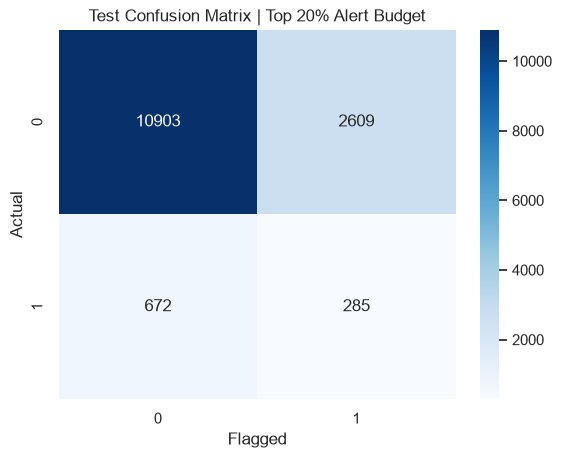

In [11]:
# ======================================================================
# 11 | Test Evaluation and Bootstrap Uncertainty
# ======================================================================

"""
Test results are retrospective because the original
test period has already been inspected.

Do not claim a new blind holdout.
"""

test_prob = selected_model.predict_proba(X_test)[:, 1]

test_metrics = evaluate(y_test, test_prob)

display(pd.DataFrame([{
    "model": selected_name,
    "test_rows": len(test),
    "test_prevalence": y_test.mean(),
    **test_metrics
}]))

# Bootstrap the test sample to quantify sampling uncertainty.
# This is an approximate iid bootstrap, not a time-block bootstrap.
bootstrap_scores = []

y_array = y_test.to_numpy()

for _ in range(500):
    idx = rng.integers(
        0, len(y_array), size=len(y_array)
    )

    y_b = y_array[idx]
    p_b = test_prob[idx]

    if y_b.sum() == 0:
        continue

    bootstrap_scores.append(
        recall_at_budget(y_b, p_b, ALERT_BUDGET)
    )

ci_low, ci_high = np.percentile(
    bootstrap_scores, [2.5, 97.5]
)

print("Test Recall@20%:", test_metrics["recall_at_20"])
print("Approximate 95% bootstrap CI:", ci_low, ci_high)

# Operational confusion matrix using top 20% selection.
k = int(np.ceil(len(test_prob) * ALERT_BUDGET))
ranked = np.argsort(-test_prob, kind="stable")

test_pred = np.zeros(len(test_prob), dtype=int)
test_pred[ranked[:k]] = 1

matrix = confusion_matrix(y_test, test_pred)

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.title("Test Confusion Matrix | Top 20% Alert Budget")
plt.xlabel("Flagged")
plt.ylabel("Actual")
plt.show()

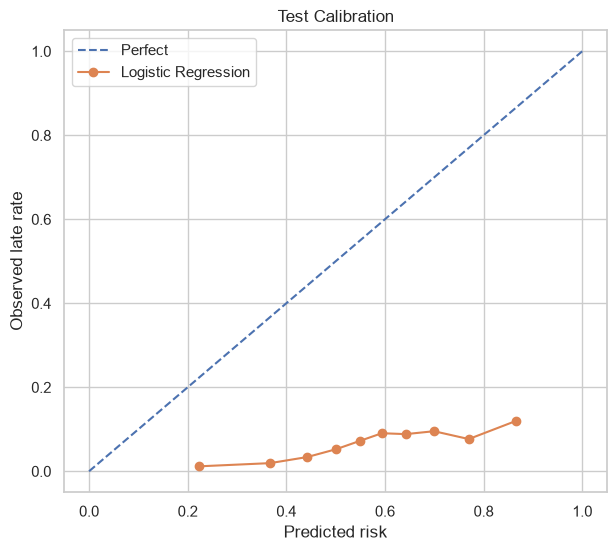

,segment_type,segment,orders,late_rate,alert_rate,precision,recall
13,customer_state,SP,6749,0.095273,0.073048,0.200811,0.153966
10,customer_state,RJ,1625,0.054154,0.462769,0.098404,0.840909
5,customer_state,MG,1581,0.020873,0.094244,0.046980,0.212121
9,customer_state,PR,743,0.032301,0.087483,0.046154,0.125000
11,customer_state,RS,720,0.033333,0.227778,0.048780,0.333333
12,customer_state,SC,462,0.034632,0.350649,0.043210,0.437500
0,customer_state,BA,458,0.048035,0.491266,0.071111,0.727273
2,customer_state,DF,355,0.039437,0.211268,0.093333,0.500000
4,customer_state,GO,275,0.040000,0.276364,0.052632,0.363636
3,customer_state,ES,272,0.047794,0.419118,0.061404,0.538462


Train prevalence: 0.09028569735926184
Validation prevalence: 0.053428255460326236
Test prevalence: 0.06614140576404727


In [12]:
# ======================================================================
# 12 | Calibration, Drift and Segment Diagnostics
# ======================================================================

from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(
    y_test,
    test_prob,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], "--", label="Perfect")
plt.plot(
    prob_pred, prob_true,
    marker="o", label=selected_name
)
plt.xlabel("Predicted risk")
plt.ylabel("Observed late rate")
plt.title("Test Calibration")
plt.legend()
plt.show()

diagnostics = test[[
    "order_id",
    "customer_state",
    "purchase_month"
]].copy()

diagnostics["actual"] = y_array
diagnostics["risk"] = test_prob
diagnostics["flagged"] = test_pred

segment_rows = []

for col in ["customer_state", "purchase_month"]:
    for value, group in diagnostics.groupby(col):
        if len(group) < 100:
            continue

        segment_rows.append({
            "segment_type": col,
            "segment": str(value),
            "orders": len(group),
            "late_rate": group.actual.mean(),
            "alert_rate": group.flagged.mean(),
            "precision": precision_score(
                group.actual,
                group.flagged,
                zero_division=0
            ),
            "recall": recall_score(
                group.actual,
                group.flagged,
                zero_division=0
            )
        })

segments = pd.DataFrame(segment_rows)

display(
    segments.sort_values(
        ["segment_type", "orders"],
        ascending=[True, False]
    ).head(25)
)

print("Train prevalence:", y_train.mean())
print("Validation prevalence:", y_valid.mean())
print("Test prevalence:", y_test.mean())

/opt/anaconda3/envs/retailai-nlp/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,feature,importance
19,categorical__customer_state_AL,0.966138
51,categorical__seller_state_MA,0.826788
38,categorical__customer_state_RO,0.802202
36,categorical__customer_state_RJ,0.677511
0,numeric__promised_days,0.677037
35,categorical__customer_state_PR,0.578280
63,categorical__seller_state_RS,0.541557
50,categorical__seller_state_GO,0.498042
60,categorical__seller_state_RJ,0.492081
28,categorical__customer_state_MG,0.488232


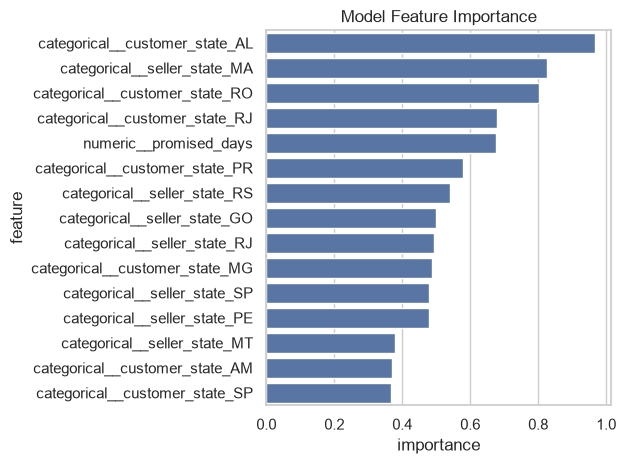

Attribution explains predictions, not causal relationships.


In [13]:
# ======================================================================
# 13 | Explainability and Feature Importance
# ======================================================================

import shap

preprocessor = selected_model.named_steps["preprocessor"]
estimator = selected_model.named_steps["model"]

sample = X_test.sample(
    n=min(300, len(X_test)),
    random_state=SEED
)

encoded = preprocessor.transform(sample)
feature_names = preprocessor.get_feature_names_out()

if isinstance(
    estimator,
    (RandomForestClassifier, XGBClassifier)
):
    explainer = shap.TreeExplainer(estimator)
    values = explainer.shap_values(encoded)

    if isinstance(values, list):
        values = values[-1]

    values = np.asarray(values)

    if values.ndim == 3:
        values = values[:, :, -1]

    importance_values = np.abs(values).mean(axis=0)

elif isinstance(estimator, LogisticRegression):
    importance_values = np.abs(
        estimator.coef_[0]
    )

elif hasattr(estimator, "feature_importances_"):
    importance_values = estimator.feature_importances_

else:
    # Permutation importance is model-agnostic.
    from sklearn.inspection import permutation_importance

    perm = permutation_importance(
        selected_model,
        X_valid,
        y_valid,
        scoring="average_precision",
        n_repeats=3,
        random_state=SEED,
        n_jobs=2
    )

    feature_names = np.asarray(features)
    importance_values = perm.importances_mean

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_values
}).sort_values("importance", ascending=False)

display(importance.head(20))

sns.barplot(
    data=importance.head(15),
    x="importance",
    y="feature"
)
plt.title("Model Feature Importance")
plt.tight_layout()
plt.show()

print(
    "Attribution explains predictions, "
    "not causal relationships."
)

In [14]:
# ======================================================================
# 14 | Export Model, Reports and Final Checks
# ======================================================================

artifact = {
    "pipeline": selected_model,
    "model_name": selected_name,
    "feature_columns": features,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "alert_budget": ALERT_BUDGET,
    "prediction_stage": "post_approval",
    "target": "late_delivery",
    "random_state": SEED
}

model_path = MODELS / "late_delivery_risk_model_v2.joblib"
joblib.dump(artifact, model_path)

loaded = joblib.load(model_path)

sample_predictions = loaded["pipeline"].predict_proba(
    X_test.iloc[:10]
)[:, 1]

assert np.allclose(
    sample_predictions,
    test_prob[:10]
)

comparison.to_csv(
    REPORTS / "model_v2_comparison.csv",
    index=False
)
capacity.to_csv(
    REPORTS / "model_v2_capacity.csv",
    index=False
)
segments.to_csv(
    REPORTS / "model_v2_segments.csv",
    index=False
)
importance.to_csv(
    REPORTS / "model_v2_importance.csv",
    index=False
)

metrics_path = REPORTS / "model_v2_test_metrics.csv"

pd.DataFrame([{
    "model": selected_name,
    "test_rows": len(test),
    **test_metrics,
    "recall_20_ci_low": ci_low,
    "recall_20_ci_high": ci_high
}]).to_csv(metrics_path, index=False)

metadata = {
    "model": selected_name,
    "alert_budget": ALERT_BUDGET,
    "test_metrics": {
        k: float(v)
        for k, v in test_metrics.items()
    },
    "limitations": [
        "Historical delivered-order selection bias",
        "Retrospective previously inspected test period",
        "Approximate multi-seller geographic origin",
        "Approximate iid bootstrap confidence interval",
        "Feature availability requires production verification",
        "Seller history includes only observed delivered orders",
        "No causal or production-readiness claim"
    ]
}

(MODELS / "late_delivery_model_v2_metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

print("=" * 65)
print("RETAILAI MODEL V2 COMPLETE")
print("=" * 65)
print("Selected:", selected_name)
print("Test Recall@20%:", test_metrics["recall_at_20"])
print("Test Precision@20%:", test_metrics["precision_at_20"])
print("Test PR-AUC:", test_metrics["pr_auc"])
print("Test ROC-AUC:", test_metrics["roc_auc"])
print("Model:", model_path)
print("Reports:", REPORTS)
print("NOTE: Retrospective evaluation, not blind validation.")

RETAILAI MODEL V2 COMPLETE
Selected: Logistic Regression
Test Recall@20%: 0.29780564263322884
Test Precision@20%: 0.09847961299239806
Test PR-AUC: 0.10653665006055853
Test ROC-AUC: 0.6495732266005434
Model: /Users/adityachaubey/Desktop/RetailAI/models/late_delivery_risk_model_v2.joblib
Reports: /Users/adityachaubey/Desktop/RetailAI/reports
NOTE: Retrospective evaluation, not blind validation.
